# Chapitre 9 - Cours 1 : la linéarisabilité

Répliquer les données protège des pannes, mais crée des copies qui peuvent diverger.
La garantie la plus forte qu'un système répliqué puisse offrir est de **se comporter
comme s'il n'existait qu'une seule copie** des données : c'est la **linéarisabilité**.
Ce notebook la définit précisément, construit un **vérificateur** qui décide si un
historique d'opérations est linéarisable, l'applique à des systèmes simulés (un registre
sur quorum, en particulier) et mesure ce qu'elle coûte. Il couvre la section *Consistency Guarantees* et toute la section *Linearizability* (*What Makes a System Linearizable?*, *Relying on Linearizability*, *Implementing Linearizable Systems*, *The Cost of Linearizability*) du chapitre.

**Plan.**

1. Cohérence à terme ou cohérence forte : l'illusion d'une copie unique.
2. Qu'est-ce qui rend un système linéarisable ? Un vérificateur exécutable.
3. Linéarisabilité contre sérialisabilité.
4. Quand a-t-on besoin de linéarisabilité ?
5. Quelles réplications sont linéarisables ? Le piège des quorums.
6. Le coût de la linéarisabilité : CAP et délais réseau.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.consistency import Op
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Cohérence à terme ou cohérence forte : l'illusion d'une copie unique (section *Consistency Guarantees*)

Au chapitre 5, nous avons vu qu'une base répliquée peut renvoyer des
résultats **périmés** (une réplique en retard) ou **contradictoires** (des écritures
concurrentes sur plusieurs leaders). Deux philosophies s'opposent pour vivre avec :

- la **cohérence à terme** (eventual consistency) : la réplication est visible de
  l'application, qui doit gérer elle-même les incohérences et les conflits ; la seule
  promesse est que les répliques **convergent** si l'on cesse d'écrire. Promesse faible :
  elle ne dit rien de **quand** ;
- la **cohérence forte** : le système masque la réplication et se comporte **comme un
  seul nœud**. C'est plus simple pour le développeur, mais plus lent, et certaines pannes
  qu'un système à cohérence à terme tolère le rendent indisponible.

Le livre compare ces garanties aux niveaux d'isolation des transactions du chapitre
7 : dans les deux cas, on échange de la simplicité contre de la
performance. Mais les deux hiérarchies répondent à des questions différentes :
l'isolation traite des **courses entre transactions concurrentes**, les modèles de
cohérence de la **coordination des répliques** face aux délais et aux pannes. Ce chapitre
explore le modèle le plus fort courant (la linéarisabilité), les garanties d'**ordre**
(causalité, ordre total) et enfin le **consensus**.

**L'idée de la linéarisabilité** (aussi appelée cohérence atomique, cohérence forte,
cohérence immédiate ou externe) : le système doit donner l'**illusion d'une copie unique**
des données, sur laquelle chaque opération s'exécute **atomiquement**. Conséquence
directe : dès qu'une écriture est terminée, **toute** lecture qui commence ensuite, par
n'importe quel client, voit la nouvelle valeur. C'est une **garantie de fraîcheur**
(recency guarantee).

Voici un système qui ne la respecte pas. Inès et Bastien suivent sur leur téléphone la
finale de leur équipe. Le score final est écrit sur le leader, qui le réplique de façon
asynchrone à deux suiveurs. Inès recharge la page, tombe sur le suiveur 1 (à jour), voit
le score final et **le crie** à Bastien, qui recharge à son tour... et tombe sur le
suiveur 2, en retard : pour lui le match n'est pas fini.

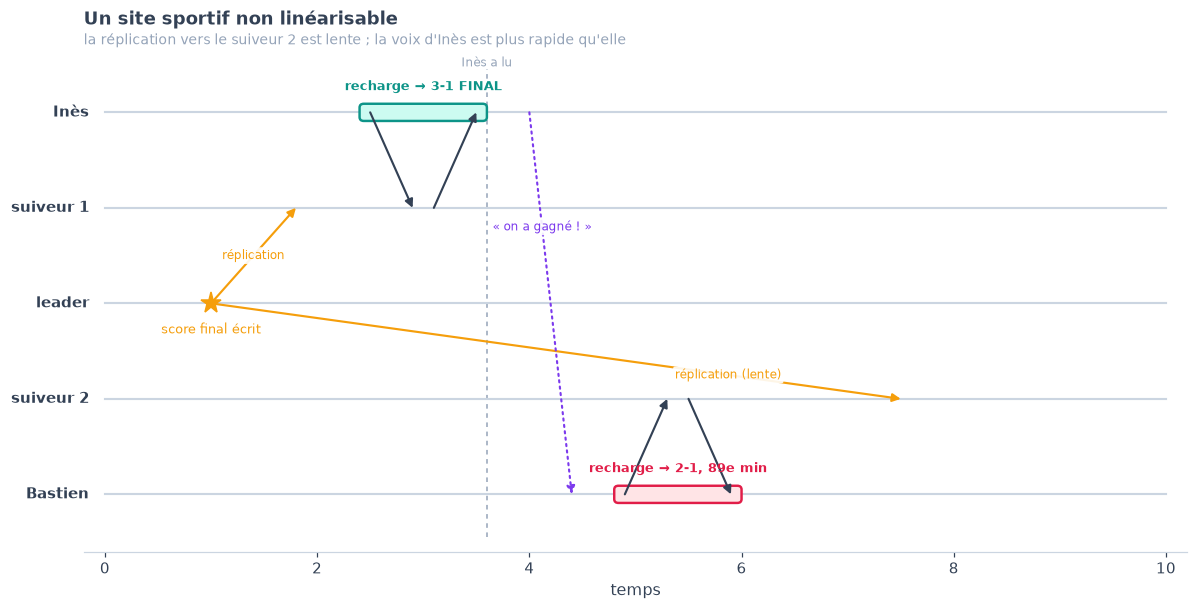

In [2]:
st = SpaceTime(["Inès", "suiveur 1", "leader", "suiveur 2", "Bastien"], t_max=10, width=11,
               title="Un site sportif non linéarisable",
               subtitle="la réplication vers le suiveur 2 est lente ; la voix d'Inès est plus rapide qu'elle")
st.event("leader", 1.0, "score final écrit", kind="star")
st.msg("leader", 1.0, "suiveur 1", 1.8, "réplication", color=AMBER)
st.msg("leader", 1.0, "suiveur 2", 7.5, "réplication (lente)", color=AMBER, label_pos=0.75)
st.op("Inès", 2.4, 3.6, "recharge → 3-1 FINAL", color=TEAL)
st.msg("Inès", 2.5, "suiveur 1", 2.9, "", color=SLATE)
st.msg("suiveur 1", 3.1, "Inès", 3.5, "", color=SLATE)
st.msg("Inès", 4.0, "Bastien", 4.4, "« on a gagné ! »", color=VIOLET, style="dotted", label_pos=0.3)
st.op("Bastien", 4.8, 6.0, "recharge → 2-1, 89e min", color=ROSE)
st.msg("Bastien", 4.9, "suiveur 2", 5.3, "", color=SLATE)
st.msg("suiveur 2", 5.5, "Bastien", 5.9, "", color=SLATE)
st.vline(3.6, "Inès a lu")
st.show()

Si les deux avaient rechargé **au même moment**, des résultats différents n'auraient
surpris personne. Mais Bastien **sait** qu'il a lancé sa requête **après** la réponse
reçue par Inès (il a entendu le cri) : il s'attend donc à un résultat au moins aussi
récent. La réponse périmée est une **violation de la linéarisabilité**. Remarquez que
l'anomalie n'est visible que grâce à un **second canal de communication** (la voix) :
nous y reviendrons en section 4.

> **À retenir.** La linéarisabilité donne l'illusion d'une copie unique, modifiée
> atomiquement : une lecture qui commence après la fin d'une écriture (ou d'une autre
> lecture) doit voir une valeur au moins aussi récente. C'est une garantie de fraîcheur.

## 2. Qu'est-ce qui rend un système linéarisable ? (section *What Makes a System Linearizable?*)

**Le modèle.** On raisonne sur un **registre** $x$ (en pratique une clé d'un magasin
clé-valeur, une ligne, un document) et sur des opérations vues **depuis les clients** :

- `read(x) ⇒ v` : le client lit $x$ et la base répond $v$ ;
- `write(x, v) ⇒ ok` : le client écrit $v$ dans $x$ ;
- `cas(x, old, new) ⇒ ok / échec` : compare-and-set atomique, qui écrit `new` seulement
  si la valeur courante vaut `old` (chapitre 7).

Chaque opération est un **intervalle** de temps : de l'envoi de la requête à la réception
de la réponse. Le client ne sait pas **quand** la base l'a réellement traitée, seulement
que c'était **quelque part dans l'intervalle**. Deux opérations dont les intervalles se
chevauchent sont **concurrentes**.

**La définition.** Un historique est linéarisable s'il existe un **point de
linéarisation** dans l'intervalle de chaque opération tel que, rangées dans l'ordre de
ces points, les opérations forment une exécution **séquentielle valide** du registre
(chaque lecture renvoie la dernière valeur écrite avant elle). Deux conséquences :

1. si A se termine avant que B ne commence, A précède B (le temps réel est respecté) ;
2. une lecture concurrente d'une écriture peut renvoyer l'ancienne **ou** la nouvelle
   valeur, mais une fois qu'une lecture a vu la nouvelle, **toutes les lectures
   suivantes** doivent la voir : la valeur ne peut pas « clignoter ».

**Un vérificateur exécutable.** `cs.check_linearizable` cherche un tel ordre : à chaque
étape, il essaie de placer en tête une opération qui peut l'être (aucune opération
restante ne s'est terminée avant son appel) et dont le résultat est cohérent avec l'état
du registre, puis recommence ; en cas d'impasse, il revient en arrière. Il mémorise les
couples (opérations déjà placées, valeur du registre) déjà explorés : c'est
l'algorithme de Wing et Gong amélioré par Lowe, celui qu'utilisent les outils de test
comme Knossos (Jepsen) ou Porcupine. Appliquons-le à trois historiques où C écrit 1
pendant que A et B lisent.

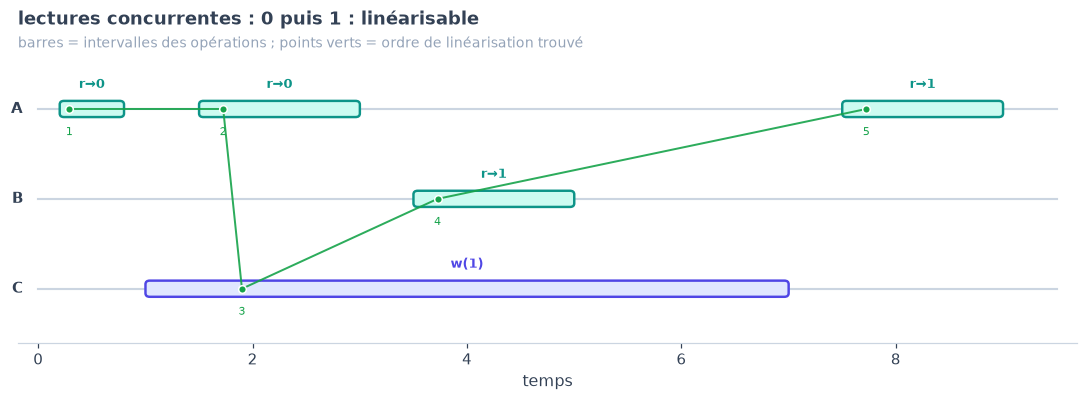

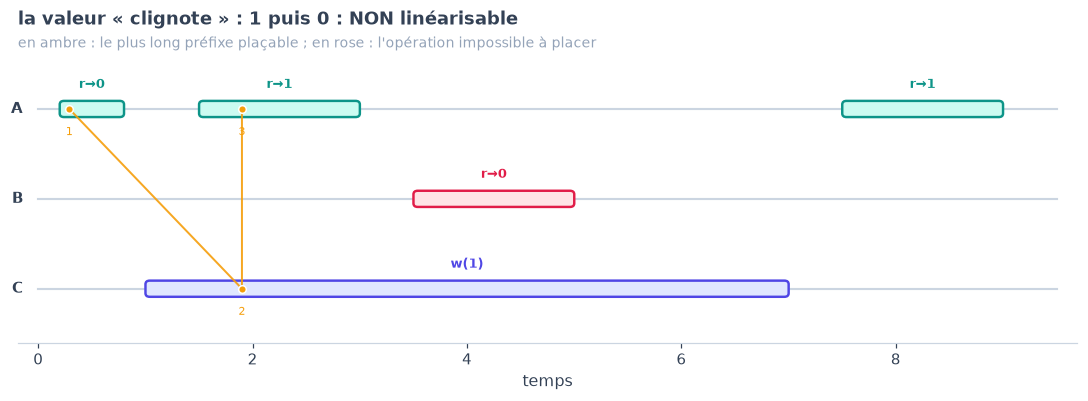

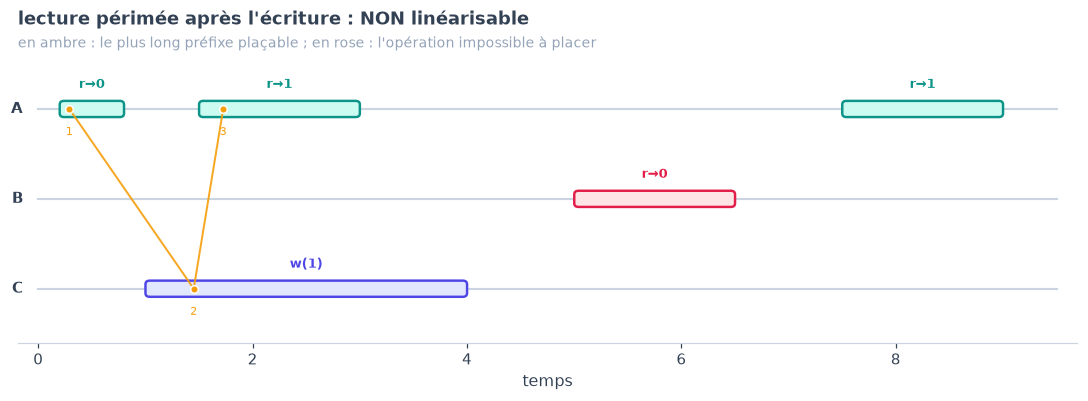

,historique,linéarisable,états_explorés
0,lectures concurrentes : 0 puis 1,True,6
1,la valeur « clignote » : 1 puis 0,False,4
2,lecture périmée après l'écriture,False,4


In [3]:
H = {
    "lectures concurrentes : 0 puis 1": [Op("C", "write", 1, "ok", 1.0, 7.0), Op("A", "read", None, 0, 0.2, 0.8),
                                       Op("A", "read", None, 0, 1.5, 3.0), Op("B", "read", None, 1, 3.5, 5.0),
                                       Op("A", "read", None, 1, 7.5, 9.0)],
    "la valeur « clignote » : 1 puis 0": [Op("C", "write", 1, "ok", 1.0, 7.0), Op("A", "read", None, 0, 0.2, 0.8),
                                        Op("A", "read", None, 1, 1.5, 3.0), Op("B", "read", None, 0, 3.5, 5.0),
                                        Op("A", "read", None, 1, 7.5, 9.0)],
    "lecture périmée après l'écriture": [Op("C", "write", 1, "ok", 1.0, 4.0), Op("A", "read", None, 0, 0.2, 0.8),
                                       Op("A", "read", None, 1, 1.5, 3.0), Op("B", "read", None, 0, 5.0, 6.5),
                                       Op("A", "read", None, 1, 7.5, 9.0)],
}
rows = []
for nom, h in H.items():
    res = cs.check_linearizable(h)
    rows.append(dict(historique=nom, linéarisable=res.ok, états_explorés=res.explored))
    st = cs.plot_history(h, title=f"{nom} : {'linéarisable' if res.ok else 'NON linéarisable'}",
                         subtitle="barres = intervalles des opérations ; points verts = ordre de linéarisation trouvé"
                         if res.ok else "en ambre : le plus long préfixe plaçable ; en rose : l'opération impossible à placer",
                         result=res, clients=["A", "B", "C"], t_max=9.5, width=10,
                         highlight=res.blocking(h)[:1])
    st.show()
pd.DataFrame(rows)

Dans le premier historique, la lecture de B (qui renvoie 1) est concurrente de
l'écriture : le vérificateur place l'écriture **à l'intérieur** de son intervalle, juste
avant la lecture de B. Dans le deuxième, A a vu 1 puis B, qui commence **après** la
réponse à A, voit 0 : aucun placement des points ne permet de revenir à l'ancienne valeur.
C'est exactement la situation d'Inès et Bastien. Dans le troisième, B lit 0 alors que
l'écriture est **terminée** avant même le début de sa lecture.

**Un exemple plus riche, avec des CAS.** Quatre clients, des écritures concurrentes et
des compare-and-set. Les requêtes ne sont pas traitées dans l'ordre d'envoi : c'est
permis tant qu'elles sont concurrentes (un message a pu être retardé sur le réseau).

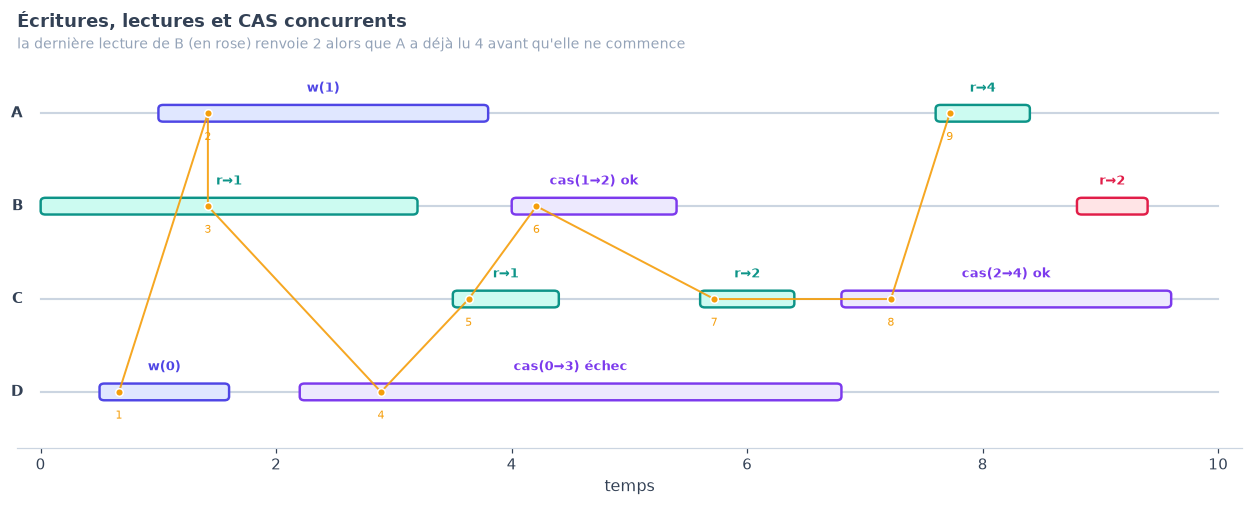

linéarisable : False ; opérations placées : 9 sur 10
ordre partiel trouvé : w(0) (D) ; w(1) (A) ; r→1 (B) ; cas(0→3) échec (D) ; r→1 (C) ; cas(1→2) ok (B) ; r→2 (C) ; cas(2→4) ok (C) ; r→4 (A)


In [4]:
riche = [
    Op("B", "read", None, 1, 0.0, 3.2),
    Op("D", "write", 0, "ok", 0.5, 1.6),
    Op("A", "write", 1, "ok", 1.0, 3.8),
    Op("C", "read", None, 1, 3.5, 4.4),
    Op("B", "cas", (1, 2), True, 4.0, 5.4),
    Op("C", "read", None, 2, 5.6, 6.4),
    Op("D", "cas", (0, 3), False, 2.2, 6.8),
    Op("C", "cas", (2, 4), True, 6.8, 9.6),
    Op("A", "read", None, 4, 7.6, 8.4),
    Op("B", "read", None, 2, 8.8, 9.4),
]
res = cs.check_linearizable(riche)
st = cs.plot_history(riche, title="Écritures, lectures et CAS concurrents",
                     subtitle="la dernière lecture de B (en rose) renvoie 2 alors que A a déjà lu 4 avant qu'elle ne commence",
                     result=res, clients=["A", "B", "C", "D"], t_max=10, width=11.5, highlight=res.blocking(riche)[:1])
st.show()
print("linéarisable :", res.ok, "; opérations placées :", len(res.order), "sur", len(riche))
print("ordre partiel trouvé :", " ; ".join(cs.op_label(riche[i]) + f" ({riche[i].client})" for i in res.order))

Les neuf premières opérations se linéarisent (ligne ambre) : la base a traité
l'écriture de D, puis celle de A, puis la lecture de B (qui renvoie donc 1 bien qu'elle
ait été envoyée **avant** les deux écritures) ; le CAS de D échoue car la valeur n'est
plus 0 ; ceux de B puis de C réussissent. La dernière lecture de B est concurrente du
CAS de C qui fait passer $x$ de 2 à 4 : seule, elle pourrait renvoyer 2. Mais A a **déjà
lu 4** avant que la lecture de B ne commence : B n'a plus le droit de voir une valeur
plus ancienne.

Tester la linéarisabilité d'un vrai système revient à enregistrer les instants de toutes
les requêtes et réponses, puis à chercher un ordre valide : c'est ce que fait Jepsen. Le
problème est NP-complet dans le cas général ; la mémoïsation le rend praticable sur des
historiques courts (l'exercice 9.2 mesure ce coût).

**Modèles plus faibles.** Comme il existe des niveaux d'isolation plus faibles que la
sérialisabilité, il existe des modèles de cohérence plus faibles que la linéarisabilité :
lire ses propres écritures, lectures monotones, préfixe cohérent (chapitre
5). La linéarisabilité les implique tous : c'est le modèle le plus fort
d'usage courant.

> **À retenir.** Un historique est linéarisable si l'on peut placer dans l'intervalle de
> chaque opération un point instantané tel que la suite des points soit une exécution
> séquentielle valide. On le teste en cherchant cet ordre : c'est coûteux mais exécutable.

## 3. Linéarisabilité contre sérialisabilité (encadré *Linearizability Versus Serializability*)

Les deux mots évoquent « un ordre séquentiel », mais ce sont deux garanties différentes :

| | Sérialisabilité | Linéarisabilité |
|---|---|---|
| porte sur | des **transactions** (plusieurs objets) | des opérations sur **un objet** (registre) |
| promet | même résultat qu'une exécution en série, dans **un** ordre quelconque | ordre compatible avec le **temps réel** |
| empêche le write skew ? | oui | non (pas de transactions) |
| interdit les lectures périmées ? | non | oui (garantie de fraîcheur) |

Une base peut offrir les deux : on parle alors de **sérialisabilité stricte** (strict
serializability, ou strong one-copy serializability). Un SGBD sur un seul nœud est en
général linéarisable. Pour une base distribuée qui utilise une méthode optimiste comme
SSI (chapitre 7), c'est plus délicat : la sérialisabilité stricte exige
une coordination coûteuse entre transactions, que certaines bases offrent (Spanner,
FoundationDB) et d'autres non (CockroachDB garantit la sérialisabilité et une partie
seulement de la fraîcheur). Les deux axes sont d'ailleurs largement **indépendants**.

Un exemple montre qu'une exécution peut être sérialisable sans être linéarisable : la
transaction T2 commence **après** la validation de T1 mais lit un **instantané ancien**
(une réplique en retard, par exemple). L'ordre série « T2 puis T1 » explique ses
lectures : c'est sérialisable. Mais T2 ne voit pas une écriture terminée avant son
début : ce n'est pas linéarisable.

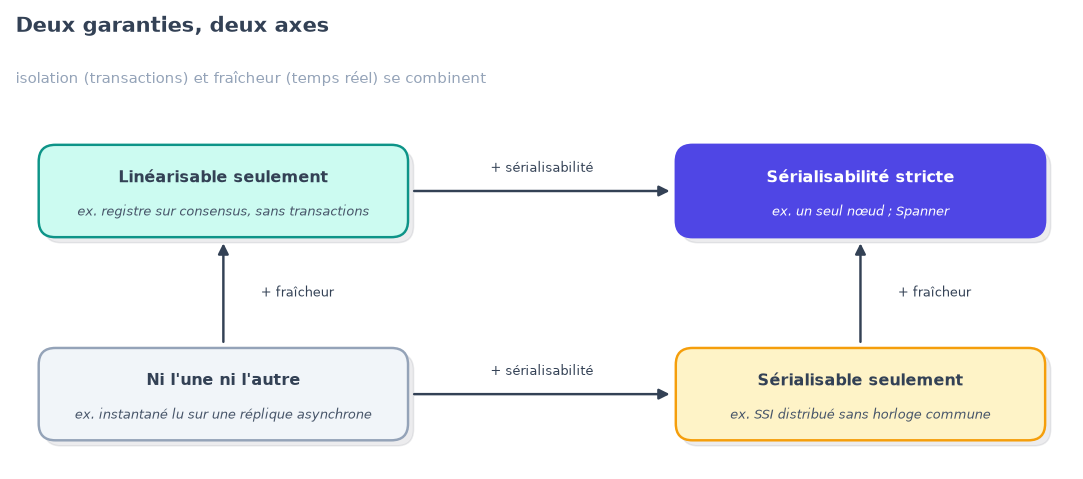

In [5]:
d = Diagram(11.5, 4.0, title="Deux garanties, deux axes", subtitle="isolation (transactions) et fraîcheur (temps réel) se combinent")
d.box("aucune", 2.3, 0.8, "Ni l'une ni l'autre", sub="ex. instantané lu sur une réplique asynchrone", color=GRAY, w=4.0, h=1.0)
d.box("ser", 9.2, 0.8, "Sérialisable seulement", sub="ex. SSI distribué sans horloge commune", color=AMBER, w=4.0, h=1.0)
d.box("lin", 2.3, 3.0, "Linéarisable seulement", sub="ex. registre sur consensus, sans transactions", color=TEAL, w=4.0, h=1.0)
d.box("strict", 9.2, 3.0, "Sérialisabilité stricte", sub="ex. un seul nœud ; Spanner", color=INDIGO, w=4.0, h=1.0, filled=True)
d.arrow("aucune", "ser", "+ sérialisabilité", label_offset=(0, 0.25))
d.arrow("aucune", "lin", "+ fraîcheur", label_offset=(0.8, 0))
d.arrow("lin", "strict", "+ sérialisabilité", label_offset=(0, 0.25))
d.arrow("ser", "strict", "+ fraîcheur", label_offset=(0.8, 0))
d.show()

> **À retenir.** Sérialisabilité : des transactions qui se comportent comme si elles
> étaient exécutées en série, dans un ordre quelconque. Linéarisabilité : un objet qui se
> comporte comme une copie unique, dans l'ordre du temps réel. Les deux ensemble forment
> la sérialisabilité stricte.